# Baseline Comparison Study

Compare DTW+OT+Centroid method against three baselines:
1. Centroid Nearest Neighbor
2. Hungarian Assignment
3. Neighborhood Structure Matching

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
import warnings
warnings.filterwarnings('ignore')
import os
import copy
from scipy.optimize import linear_sum_assignment

# Import from main reconstruction script
from cell_matching_utils import (
    load_cells_from_csv_files,
    dtw_distance_gpu_single,
    get_cluster_cells,
    compute_ot_cost_matrix,
    solve_optimal_transport,
    DTW_NORM_DIVISOR,
    OT_NORM_DIVISOR,
    CENTROID_NORM_DIVISOR,
    NUM_CONTOUR_POINTS
)

# Plotting settings
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 7
plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['xtick.major.width'] = 0.5
plt.rcParams['ytick.major.width'] = 0.5
plt.rcParams['figure.dpi'] = 150  # Adjusted for notebook display
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

WINDOW_SIZE = 200  

In [2]:
def solve_ot_with_adaptive_reg(C, weights_a, weights_b):
    """
    OT solver with adaptive regularization based on cost matrix statistics.
    Uses adaptive reg = max(C.max / 10, 50000) to prevent numerical underflow.
    """
    C_max = np.max(C)
    adaptive_reg = max(C_max / 10.0, 50000.0)
    
    original_reg = recon_module.SINKHORN_REG
    recon_module.SINKHORN_REG = adaptive_reg
    
    try:
        ot_distance, T = recon_module.solve_optimal_transport(C, weights_a, weights_b, use_gpu=True)
        return ot_distance, T
    finally:
        recon_module.SINKHORN_REG = original_reg

In [3]:
def uniform_resample_contour(contour, target_num_points):
    """Uniformly resample contour points"""
    if len(contour) == target_num_points:
        return contour
    
    if not np.allclose(contour[0], contour[-1]):
        contour = np.vstack([contour, contour[0:1]])
    
    dists = np.sqrt(np.sum(np.diff(contour, axis=0)**2, axis=1))
    cumulative_dists = np.concatenate([[0], np.cumsum(dists)])
    total_length = cumulative_dists[-1]
    
    if total_length == 0:
        return np.tile(contour[0], (target_num_points, 1))
    
    target_dists = np.linspace(0, total_length, target_num_points)
    resampled_x = np.interp(target_dists, cumulative_dists, contour[:, 0])
    resampled_y = np.interp(target_dists, cumulative_dists, contour[:, 1])
    
    return np.column_stack([resampled_x, resampled_y])

def get_candidates_in_window(anchor, candidates, window_size=100):
    """Get candidate cells within spatial window"""
    cx, cy = anchor.centroid
    window_half = window_size / 2.0
    
    valid_candidates = []
    for candidate in candidates:
        cx2, cy2 = candidate.centroid
        if abs(cx2 - cx) <= window_half and abs(cy2 - cy) <= window_half:
            valid_candidates.append(candidate)
    
    return valid_candidates

def center_contour_at_origin(contour, centroid):
    """Center contour at origin by subtracting centroid
    
    DEPRECATED: Contours in cell-002_processed are already relative coordinates.
    Kept for backward compatibility only.
    """
    return contour - np.array(centroid)

In [4]:
def calculate_our_method_features(cell1, cell2, cells_by_slice):
    """Calculate features for our method: DTW + OT + Centroid
    
    Note: Contours in cell-002_processed are already centered relative to centroid,
    so we use them directly without additional centering.
    """
    features = {}
    
    # DTW (contours already centered in CSV data)
    try:
        if hasattr(cell1, 'contour_points_200') and hasattr(cell2, 'contour_points_200'):
            dtw_raw = dtw_distance_gpu_single(cell1.contour_points_200, cell2.contour_points_200)
        else:
            contour1 = uniform_resample_contour(cell1.contour_points, NUM_CONTOUR_POINTS)
            contour2 = uniform_resample_contour(cell2.contour_points, NUM_CONTOUR_POINTS)
            dtw_raw = dtw_distance_gpu_single(contour1, contour2)
        dtw_loss = min(10.0, dtw_raw / DTW_NORM_DIVISOR * 10.0)
        features['dtw_loss'] = dtw_loss
    except:
        features['dtw_loss'] = 10.0
    
    # OT (contours already centered in CSV data)
    try:
        cluster1 = get_cluster_cells(cell1, cells_by_slice)
        cluster2 = get_cluster_cells(cell2, cells_by_slice)
        if len(cluster1) > 1 and len(cluster2) > 1:
            # Use clusters directly (contours already centered)
            C = compute_ot_cost_matrix(cluster1, cluster2)
            areas1 = np.array([c.area for c in cluster1])
            areas2 = np.array([c.area for c in cluster2])
            weights1 = areas1 / areas1.sum()
            weights2 = areas2 / areas2.sum()
            ot_raw, _ = solve_ot_with_adaptive_reg(C, weights1, weights2)
            features['ot_loss'] = min(10.0, ot_raw / OT_NORM_DIVISOR * 10.0)
        else:
            features['ot_loss'] = 0.0
    except:
        features['ot_loss'] = 10.0
    
    # Centroid distance
    cx1, cy1 = cell1.centroid
    cx2, cy2 = cell2.centroid
    centroid_dist = np.sqrt((cx2 - cx1)**2 + (cy2 - cy1)**2)
    features['centroid_loss'] = min(10.0, centroid_dist / CENTROID_NORM_DIVISOR * 10.0)
    
    return features


# Baseline 1: Centroid Nearest Neighbor

In [5]:
def baseline1_centroid_nearest(anchor, candidates, cells_by_slice=None):
    """Find nearest neighbor based on centroid distance"""
    if len(candidates) == 0:
        return None, float('inf')
    
    cx1, cy1 = anchor.centroid
    min_dist = float('inf')
    best_candidate = None
    
    for candidate in candidates:
        cx2, cy2 = candidate.centroid
        dist = np.sqrt((cx2 - cx1)**2 + (cy2 - cy1)**2)
        if dist < min_dist:
            min_dist = dist
            best_candidate = candidate
    
    return best_candidate, min_dist


# Baseline 2: Hungarian Assignment

In [6]:
def baseline2_hungarian_matching(anchors, candidates, window_size=100):
    """Global optimal matching using Hungarian algorithm"""
    n_anchors = len(anchors)
    n_candidates = len(candidates)
    
    if n_anchors == 0 or n_candidates == 0:
        return {}
    
    # Build cost matrix
    cost_matrix = np.zeros((n_anchors, n_candidates))
    
    for i, anchor in enumerate(anchors):
        cx1, cy1 = anchor.centroid
        area1 = anchor.area
        
        for j, candidate in enumerate(candidates):
            cx2, cy2 = candidate.centroid
            area2 = candidate.area
            
            centroid_dist = np.sqrt((cx2 - cx1)**2 + (cy2 - cy1)**2)
            area_ratio = abs(area1 - area2) / max(area1, area2) if max(area1, area2) > 0 else 1.0
            
            window_half = window_size / 2.0
            if abs(cx2 - cx1) > window_half or abs(cy2 - cy1) > window_half:
                cost = 1e6
            else:
                normalized_dist = centroid_dist / window_size
                cost = normalized_dist + 0.5 * area_ratio
            
            cost_matrix[i, j] = cost
    
    # Solve assignment
    row_indices, col_indices = linear_sum_assignment(cost_matrix)
    
    matching = {}
    for i, j in zip(row_indices, col_indices):
        if cost_matrix[i, j] < 100:
            matching[anchors[i].cell_id] = candidates[j].cell_id
    
    return matching


# Baseline 3: Neighborhood Structure

In [7]:
def build_adjacency_graph(cells, distance_threshold=100):
    """Build adjacency graph for cells on a slice"""
    adjacency = {}
    
    for i, cell in enumerate(cells):
        neighbors = []
        cx1, cy1 = cell.centroid
        
        for j, other_cell in enumerate(cells):
            if i == j:
                continue
            
            cx2, cy2 = other_cell.centroid
            dist = np.sqrt((cx2 - cx1)**2 + (cy2 - cy1)**2)
            
            if dist <= distance_threshold:
                neighbors.append(other_cell.cell_id)
        
        adjacency[cell.cell_id] = neighbors
    
    return adjacency

def compute_neighbor_direction_histogram(cell, neighbors_cells, n_bins=8):
    """Compute histogram of neighbor directions"""
    if len(neighbors_cells) == 0:
        return np.zeros(n_bins)
    
    cx, cy = cell.centroid
    angles = []
    
    for neighbor in neighbors_cells:
        nx, ny = neighbor.centroid
        angle = np.arctan2(ny - cy, nx - cx)
        angles.append(angle)
    
    angles = [(a + 2*np.pi) % (2*np.pi) for a in angles]
    hist, _ = np.histogram(angles, bins=n_bins, range=(0, 2*np.pi))
    
    if hist.sum() > 0:
        hist = hist / hist.sum()
    
    return hist

def baseline3_neighborhood_matching(anchor, candidates, cells_by_slice, adjacency_prev, adjacency_next):
    """Match based on centroid distance + neighborhood structure"""
    if len(candidates) == 0:
        return None, float('inf')
    
    cx1, cy1 = anchor.centroid
    
    # Get anchor neighbors
    anchor_neighbors = adjacency_prev.get(anchor.cell_id, [])
    anchor_neighbor_cells = [c for c in cells_by_slice.get(anchor.slice_index, []) 
                            if c.cell_id in anchor_neighbors]
    anchor_dir_hist = compute_neighbor_direction_histogram(anchor, anchor_neighbor_cells)
    anchor_n_neighbors = len(anchor_neighbors)
    
    best_score = float('inf')
    best_candidate = None
    
    for candidate in candidates:
        cx2, cy2 = candidate.centroid
        centroid_dist = np.sqrt((cx2 - cx1)**2 + (cy2 - cy1)**2)
        
        candidate_neighbors = adjacency_next.get(candidate.cell_id, [])
        candidate_neighbor_cells = [c for c in cells_by_slice.get(candidate.slice_index, [])
                                   if c.cell_id in candidate_neighbors]
        candidate_dir_hist = compute_neighbor_direction_histogram(candidate, candidate_neighbor_cells)
        candidate_n_neighbors = len(candidate_neighbors)
        
        neighbor_count_diff = abs(anchor_n_neighbors - candidate_n_neighbors)
        dir_hist_diff = np.linalg.norm(anchor_dir_hist - candidate_dir_hist)
        
        normalized_dist = centroid_dist / 100.0
        normalized_count_diff = neighbor_count_diff / max(1, max(anchor_n_neighbors, candidate_n_neighbors))
        
        score = (0.5 * normalized_dist + 
                0.25 * normalized_count_diff + 
                0.25 * dir_hist_diff)
        
        if score < best_score:
            best_score = score
            best_candidate = candidate
    
    return best_candidate, best_score


In [8]:
# Anchor Set Functions
def get_valid_anchor_set(golden_df, cells_by_slice, window_size=100):
    """
    Get valid anchor set from original data (no transformation).
    Ensures consistent anchor set across all transformations.
    """
    valid_anchors = set()
    
    for idx, row in golden_df.iterrows():
        start_layer = row['Start_layer']
        end_layer = row['End_layer']
        start_cell_id = row['Start_cell']
        
        if end_layer - start_layer != 1:
            continue
        
        anchor = None
        for c in cells_by_slice.get(start_layer, []):
            if c.cell_id == start_cell_id:
                anchor = c
                break
        
        if anchor is None:
            continue
        
        candidates = cells_by_slice.get(end_layer, [])
        candidates_in_window = get_candidates_in_window(anchor, candidates, window_size)
        
        if len(candidates_in_window) > 0:
            anchor_id = f"L{start_layer}_{start_cell_id}"
            valid_anchors.add(anchor_id)
    
    return valid_anchors

def get_fixed_anchor_set_where_true_in_window(golden_df, cells_by_slice, window_size=100):
    """
    Get fixed anchor set for Our Method: only keep anchors where
    the golden true_match is within the window candidates.
    """
    fixed = set()
    
    # Build index for faster lookup
    index = {}
    for s, cells in cells_by_slice.items():
        index[s] = {c.cell_id: c for c in cells}
    
    for _, row in golden_df.iterrows():
        s = row['Start_layer']
        t = row['End_layer']
        if t - s != 1:
            continue
        
        start_id = row['Start_cell']
        true_id = row['End_cell']
        
        anchor = index.get(s, {}).get(start_id, None)
        if anchor is None:
            continue
        
        candidates = cells_by_slice.get(t, [])
        candidates_in_window = get_candidates_in_window(anchor, candidates, window_size)
        
        # Only include if true match appears in window candidates
        if any(c.cell_id == true_id for c in candidates_in_window):
            fixed.add(f"L{s}_{start_id}")
    
    return fixed

In [9]:
def evaluate_method_on_golden_pairs(golden_df, cells_by_slice, method_name, method_func, 
                                   valid_anchor_set=None, **method_kwargs):
    """Evaluate a matching method on golden standard pairs"""
    print(f"\n  Evaluating {method_name}...")
    
    results = []
    correct_count = 0
    total_count = 0
    skipped_count = 0
    
    for idx, row in golden_df.iterrows():
        if (idx + 1) % 50 == 0:
            print(f"    Processing {idx+1}/{len(golden_df)} pairs...")
        
        start_layer = row['Start_layer']
        end_layer = row['End_layer']
        start_cell_id = row['Start_cell']
        true_match_id = row['End_cell']
        num_annotators = row['number']
        
        if end_layer - start_layer != 1:
            continue
        
        anchor = None
        for c in cells_by_slice.get(start_layer, []):
            if c.cell_id == start_cell_id:
                anchor = c
                break
        
        if anchor is None:
            continue
        
        anchor_id = f"L{start_layer}_{start_cell_id}"
        
        # If valid_anchor_set provided, only evaluate anchors in the set
        if valid_anchor_set is not None and anchor_id not in valid_anchor_set:
            skipped_count += 1
            continue
        
        candidates = cells_by_slice.get(end_layer, [])
        candidates_in_window = get_candidates_in_window(anchor, candidates, WINDOW_SIZE)
        
        candidates_in_window = get_candidates_in_window(anchor, candidates, WINDOW_SIZE)
        
        if len(candidates_in_window) == 0:
            results.append({'method': method_name, 'is_correct': False})
            total_count += 1
            continue
        
        best_match, _ = method_func(anchor, candidates_in_window, cells_by_slice, **method_kwargs)
        
        is_correct = (best_match is not None and best_match.cell_id == true_match_id)
        if is_correct:
            correct_count += 1
        total_count += 1
        
        results.append({'method': method_name, 'is_correct': is_correct})
    
    accuracy = correct_count / total_count if total_count > 0 else 0.0
    print(f"    {method_name} Accuracy: {accuracy:.4f}")
    
    return pd.DataFrame(results), accuracy


In [10]:
def evaluate_baseline2_hungarian(golden_df, cells_by_slice, valid_anchor_set=None):
    """Evaluate Baseline 2 which requires global matching per layer pair"""
    print(f"\n  Evaluating Baseline 2: Hungarian Assignment...")
    
    results = []
    correct_count = 0
    total_count = 0
    skipped_count = 0
    
    # Group by layer pairs
    layer_pairs = golden_df.groupby(['Start_layer', 'End_layer'])
    
    for (start_layer, end_layer), group in layer_pairs:
        if end_layer - start_layer != 1:
            continue
            
        print(f"    Processing layer pair {start_layer}->{end_layer}...")
        
        anchors = []
        anchor_to_true_match = {}
        anchor_to_num_annotators = {}
        
        for _, row in group.iterrows():
            start_cell_id = row['Start_cell']
            true_match_id = row['End_cell']
            num_annotators = row['number']
            
            anchor = None
            for c in cells_by_slice.get(start_layer, []):
                if c.cell_id == start_cell_id:
                    anchor = c
                    break
            
            if anchor is not None:
                anchors.append(anchor)
                anchor_to_true_match[anchor.cell_id] = true_match_id
                anchor_to_num_annotators[anchor.cell_id] = num_annotators
        
        candidates = cells_by_slice.get(end_layer, [])
        matching = baseline2_hungarian_matching(anchors, candidates, WINDOW_SIZE)
        
        for anchor in anchors:
            anchor_id = f"L{start_layer}_{anchor.cell_id}"
            
            if valid_anchor_set is not None and anchor_id not in valid_anchor_set:
                skipped_count += 1
                continue
            
            predicted_match = matching.get(anchor.cell_id)
            true_match = anchor_to_true_match[anchor.cell_id]
            
            is_correct = (predicted_match == true_match)
            if is_correct:
                correct_count += 1
            total_count += 1
            
            results.append({'method': 'Baseline 2', 'is_correct': is_correct})
    
    accuracy = correct_count / total_count if total_count > 0 else 0.0
    print(f"    Baseline 2 Accuracy: {accuracy:.4f}")
    
    return pd.DataFrame(results), accuracy


In [11]:
def evaluate_our_method_with_ml(golden_df, cells_by_slice, valid_anchor_set=None):
    """Evaluate our method (DTW+OT+Centroid) with Linear Model"""
    print(f"\n  Evaluating Our Method: DTW+OT+Centroid with Linear Model...")
    
    print("    Constructing dataset...")
    samples = []
    skipped_count = 0
    
    for idx, row in golden_df.iterrows():
        if (idx + 1) % 50 == 0:
            print(f"      Processing {idx+1}/{len(golden_df)} pairs...")
        
        start_layer = row['Start_layer']
        end_layer = row['End_layer']
        start_cell_id = row['Start_cell']
        true_match_id = row['End_cell']
        num_annotators = row['number']
        
        if end_layer - start_layer != 1:
            continue
        
        anchor = None
        for c in cells_by_slice.get(start_layer, []):
            if c.cell_id == start_cell_id:
                anchor = c
                break
        
        if anchor is None:
            continue
        
        anchor_id = f"L{start_layer}_{start_cell_id}"
        
        # If valid_anchor_set provided, only evaluate anchors in the set
        if valid_anchor_set is not None and anchor_id not in valid_anchor_set:
            skipped_count += 1
            continue
        
        candidates = cells_by_slice.get(end_layer, [])
        candidates_in_window = get_candidates_in_window(anchor, candidates, WINDOW_SIZE)
        
        # Skip if no candidates (will be marked as error later)
        if len(candidates_in_window) == 0:
            continue
        
        for candidate in candidates_in_window:
            features = calculate_our_method_features(anchor, candidate, cells_by_slice)
            label = 1 if candidate.cell_id == true_match_id else 0
            
            features['label'] = label
            features['anchor_id'] = anchor_id
            features['start_layer'] = start_layer
            features['end_layer'] = end_layer
            features['start_cell_id'] = start_cell_id
            features['end_cell_id'] = candidate.cell_id
            features['num_annotators'] = num_annotators
            
            samples.append(features)
    
    df = pd.DataFrame(samples)
    print(f"    Dataset constructed: {len(df)} samples")
    
    # Train Linear Model with GroupKFold CV
    print("    Training Linear Model with GroupKFold CV...")
    feature_names = ['dtw_loss', 'ot_loss', 'centroid_loss']
    X = df[feature_names].values
    y = df['label'].values
    anchor_ids = df['anchor_id'].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    lr_model = LogisticRegression(max_iter=1000, random_state=42,
                                  class_weight='balanced', solver='lbfgs')
    
    gkf = GroupKFold(n_splits=5)
    y_pred_scores = np.zeros(len(y))
    
    for train_idx, val_idx in gkf.split(X_scaled, y, groups=anchor_ids):
        X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
        y_train = y[train_idx]
        lr_model.fit(X_train, y_train)
        y_pred_scores[val_idx] = lr_model.predict_proba(X_val)[:, 1]
    
    # Evaluate
    print("    Evaluating predictions...")
    results = []
    correct_count = 0
    total_count = 0
    
    # Determine which anchors to evaluate
    if valid_anchor_set is not None:
        anchors_to_evaluate = valid_anchor_set
    else:
        anchors_to_evaluate = set()
        for idx, row in golden_df.iterrows():
            start_layer = row['Start_layer']
            end_layer = row['End_layer']
            start_cell_id = row['Start_cell']
            if end_layer - start_layer == 1:
                anchor_id = f"L{start_layer}_{start_cell_id}"
                if anchor_id in df['anchor_id'].values:
                    anchors_to_evaluate.add(anchor_id)
    
    # Build mapping from anchor_id to golden pair info
    anchor_to_golden_info = {}
    for idx, row in golden_df.iterrows():
        start_layer = row['Start_layer']
        end_layer = row['End_layer']
        start_cell_id = row['Start_cell']
        true_match_id = row['End_cell']
        num_annotators = row['number']
        
        if end_layer - start_layer == 1:
            anchor_id = f"L{start_layer}_{start_cell_id}"
            
            # Keep record with most annotators if multiple records exist
            if anchor_id in anchor_to_golden_info:
                if num_annotators > anchor_to_golden_info[anchor_id]['num_annotators']:
                    anchor_to_golden_info[anchor_id] = {
                        'start_layer': start_layer,
                        'end_layer': end_layer,
                        'start_cell': start_cell_id,
                        'true_match': true_match_id,
                        'num_annotators': num_annotators
                    }
            else:
                anchor_to_golden_info[anchor_id] = {
                    'start_layer': start_layer,
                    'end_layer': end_layer,
                    'start_cell': start_cell_id,
                    'true_match': true_match_id,
                    'num_annotators': num_annotators
                }
    
    for anchor_id in anchors_to_evaluate:
        total_count += 1
        
        info = anchor_to_golden_info.get(anchor_id, None)
        if info is None:
            results.append({'method': 'Our Method', 'is_correct': False})
            continue
        
        # No candidates (not in df) => mark as incorrect
        if anchor_id not in df['anchor_id'].values:
            results.append({'method': 'Our Method', 'is_correct': False})
            continue
        
        mask = (anchor_ids == anchor_id)
        anchor_df = df[mask].copy()
        anchor_df['pred_score'] = y_pred_scores[mask]
        
        # True match not in candidates => mark as incorrect
        if (anchor_df['label'] == 1).sum() == 0:
            results.append({'method': 'Our Method', 'is_correct': False})
            continue
        
        predicted_top1 = anchor_df.loc[anchor_df['pred_score'].idxmax()]
        is_correct = (predicted_top1['label'] == 1)
        if is_correct:
            correct_count += 1
        
        results.append({'method': 'Our Method', 'is_correct': is_correct})
    
    accuracy = correct_count / total_count if total_count > 0 else 0.0
    print(f"    Our Method Accuracy: {accuracy:.4f}")
    
    return pd.DataFrame(results), accuracy


In [12]:
def apply_centroid_offset_to_layer(cells, offset_x, offset_y):
    """Apply systematic centroid offset to all cells in a layer
    
    Note: contour_points_200 are stored as relative coordinates (centered at origin),
    so they remain unchanged during pure translation.
    """
    modified_cells = []
    for cell in cells:
        cell_copy = copy.deepcopy(cell)
        # Translate centroid
        cell_copy.centroid = cell_copy.centroid + np.array([offset_x, offset_y])
        # Translate absolute contour coordinates
        cell_copy.contour_points = cell_copy.contour_points + np.array([offset_x, offset_y])
        # contour_points_200 are relative coordinates - unchanged by translation
        # (This makes DTW and OT invariant to translation)
        modified_cells.append(cell_copy)
    
    return modified_cells


In [13]:
def apply_rotation_to_layer(cells, rotation_angle_deg, rotation_center=None):
    """Apply rotation transformation to all cells in a layer"""
    
    if len(cells) == 0:
        return cells
    
    # Calculate rotation center if not provided
    if rotation_center is None:
        all_centroids = np.array([cell.centroid for cell in cells])
        rotation_center = all_centroids.mean(axis=0)
    
    theta = np.radians(rotation_angle_deg)
    
    # Rotation matrix
    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    R = np.array([[cos_theta, -sin_theta],
                  [sin_theta, cos_theta]])
    
    modified_cells = []
    for cell in cells:
        cell_copy = copy.deepcopy(cell)
        
        # Rotate centroid around rotation_center
        centroid_rel = cell_copy.centroid - rotation_center
        centroid_rotated = R @ centroid_rel + rotation_center
        cell_copy.centroid = centroid_rotated
        
        # Rotate absolute contour points around rotation_center
        contour_rel = cell_copy.contour_points - rotation_center
        contour_rotated = (R @ contour_rel.T).T + rotation_center
        cell_copy.contour_points = contour_rotated
        
        # Rotate relative contour_points_200 around origin (0,0)
        # Since they are already relative coordinates, just apply rotation matrix
        if hasattr(cell_copy, 'contour_points_200') and cell_copy.contour_points_200 is not None:
            cell_copy.contour_points_200 = (R @ cell_copy.contour_points_200.T).T
        
        modified_cells.append(cell_copy)
    
    return modified_cells


In [14]:
def apply_affine_deformation_to_layer(cells, epsilon_x=0.01, epsilon_y=0.01, shear=0.01, 
                                     offset_x=0, offset_y=0, deform_center=None):
    """Apply mild affine-like deformation to all cells in a layer
    
    Note: contour_points_200 are stored as relative coordinates (centered at origin),
    so affine matrix A is applied directly, and translation offset is ignored.
    """
    if len(cells) == 0:
        return cells
    
    # Calculate deformation center if not provided
    if deform_center is None:
        all_centroids = np.array([cell.centroid for cell in cells])
        deform_center = all_centroids.mean(axis=0)
    
    # Affine transformation matrix
    A = np.array([[1 + epsilon_x, shear],
                  [shear, 1 + epsilon_y]])
    
    modified_cells = []
    for cell in cells:
        cell_copy = copy.deepcopy(cell)
        
        # Apply affine transformation to centroid around deform_center
        centroid_rel = cell_copy.centroid - deform_center
        centroid_deformed = A @ centroid_rel + deform_center + np.array([offset_x, offset_y])
        cell_copy.centroid = centroid_deformed
        
        # Apply affine transformation to absolute contour points
        contour_rel = cell_copy.contour_points - deform_center
        contour_deformed = (A @ contour_rel.T).T + deform_center + np.array([offset_x, offset_y])
        cell_copy.contour_points = contour_deformed
        
        # Apply affine matrix to relative contour_points_200 (no translation offset)
        # Since they are relative coordinates, only apply the affine matrix A
        if hasattr(cell_copy, 'contour_points_200') and cell_copy.contour_points_200 is not None:
            cell_copy.contour_points_200 = (A @ cell_copy.contour_points_200.T).T
        
        modified_cells.append(cell_copy)
    
    return modified_cells


In [15]:
def create_transformed_cells_dataset(cells_by_slice, transform_type, magnitude):
    """Create a copy of cells dataset with specified transformation applied to target layers"""
    modified_cells = {}
    
    for slice_idx, cells in cells_by_slice.items():
        # Apply transformation only to target layers (even layers)
        if slice_idx % 2 == 0:
            if transform_type == 'translation':
                offset_x = magnitude
                offset_y = magnitude
                modified_cells[slice_idx] = apply_centroid_offset_to_layer(cells, offset_x, offset_y)
            
            elif transform_type == 'rotation':
                rotation_angle = magnitude
                modified_cells[slice_idx] = apply_rotation_to_layer(cells, rotation_angle)
            
            elif transform_type == 'affine':
                epsilon = magnitude / 100.0
                modified_cells[slice_idx] = apply_affine_deformation_to_layer(
                    cells, 
                    epsilon_x=epsilon, 
                    epsilon_y=-epsilon * 0.5,
                    shear=epsilon * 0.3,
                    offset_x=0, offset_y=0
                )
            else:
                modified_cells[slice_idx] = cells
        else:
            # Odd layers (source layers) remain unchanged
            modified_cells[slice_idx] = cells
    
    return modified_cells


In [16]:
def plot_method_comparison(all_results_df, accuracies, output_dir):
    """Generate comparison visualization"""
    print("\n  Generating comparison visualization...")
    
    fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.5))
    
    methods = list(accuracies.keys())
    accs = list(accuracies.values())
    colors = ['#D62246', '#F18F01', '#06A77D', '#2E86AB']
    
    bars = ax.bar(range(len(methods)), accs, color=colors, 
                  edgecolor='black', linewidth=0.5, alpha=0.8)
    
    for i, (method, acc) in enumerate(zip(methods, accs)):
        ax.text(i, acc + 0.02, f'{acc:.3f}', ha='center', fontsize=8, fontweight='bold')
    
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels([m.split(':')[0] for m in methods], fontsize=7, rotation=15, ha='right')
    ax.set_ylabel('Accuracy', fontsize=9, fontweight='bold')
    ax.set_title('Overall Matching Accuracy', fontsize=10, fontweight='bold')
    ax.set_ylim([0, 1.1])
    ax.grid(True, alpha=0.3, linewidth=0.5, axis='y')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/method_comparison.pdf', dpi=300, bbox_inches='tight')
    plt.show()  # Display in notebook
    plt.close()
    print(f"  Saved: {output_dir}/method_comparison.pdf")


In [17]:
def plot_comprehensive_robustness_results(all_transform_results, output_dir):
    """Generate robustness visualization for individual transformation types"""
    
    methods = ['Our Method', 'Baseline 1', 'Baseline 2', 'Baseline 3']
    method_colors = ['#D62246', '#F18F01', '#06A77D', '#2E86AB']
    markers = ['o', 's', '^', 'D']
    
    # Figure 1: Individual transformations (3 panels)
    individual_transforms = ['Translation', 'Rotation', 'Affine']
    
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
    
    for idx, transform_name in enumerate(individual_transforms):
        if transform_name not in all_transform_results:
            continue
            
        ax = axes[idx]
        results_df = all_transform_results[transform_name]
        
        unit = results_df['unit'].iloc[0] if 'unit' in results_df.columns else ''
        
        # Plot accuracy vs magnitude for each method
        for i, method in enumerate(methods):
            if method in results_df.columns:
                ax.plot(results_df['magnitude'], results_df[method], 
                       marker=markers[i], color=method_colors[i], linewidth=1.5, markersize=5,
                       label=method, markeredgecolor='white', markeredgewidth=0.5,
                       alpha=0.9)
        
        ax.set_xlabel(f'Magnitude ({unit})', fontsize=8, fontweight='bold')
        ax.set_ylabel('Accuracy', fontsize=8, fontweight='bold')
        ax.set_title(f'{transform_name}', fontsize=9, fontweight='bold')
        
        if idx == 2:
            ax.legend(fontsize=6.5, loc='lower left', frameon=True, 
                     edgecolor='gray', framealpha=0.95)
        
        ax.grid(True, alpha=0.25, linewidth=0.5, linestyle='--')
        ax.set_ylim([0.3, 1.02])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/robustness_individual.pdf', dpi=300, bbox_inches='tight')
    plt.show()  # Display in notebook
    plt.close()
    print(f"  Saved: {output_dir}/robustness_individual.pdf")
    
    # Figure 2: Performance degradation (3 panels)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
    
    for idx, transform_name in enumerate(individual_transforms):
        if transform_name not in all_transform_results:
            continue
            
        ax = axes[idx]
        results_df = all_transform_results[transform_name]
        
        unit = results_df['unit'].iloc[0] if 'unit' in results_df.columns else ''
        
        # Plot relative performance drop
        for i, method in enumerate(methods):
            if method in results_df.columns:
                accs = results_df[method].values
                baseline_acc = accs[0]
                if baseline_acc > 0:
                    relative_drop = (baseline_acc - accs) / baseline_acc * 100
                else:
                    relative_drop = np.zeros_like(accs)
                
                ax.plot(results_df['magnitude'], relative_drop, 
                       marker=markers[i], color=method_colors[i], linewidth=1.5, markersize=5,
                       label=method, markeredgecolor='white', markeredgewidth=0.5,
                       alpha=0.9)
        
        ax.set_xlabel(f'Magnitude ({unit})', fontsize=8, fontweight='bold')
        ax.set_ylabel('Performance Drop (%)', fontsize=8, fontweight='bold')
        ax.set_title(f'{transform_name}', fontsize=9, fontweight='bold')
        
        if idx == 2:
            ax.legend(fontsize=6.5, loc='upper left', frameon=True, 
                     edgecolor='gray', framealpha=0.95)
        
        ax.grid(True, alpha=0.25, linewidth=0.5, linestyle='--')
        ax.axhline(0, color='gray', linestyle='-', linewidth=1, alpha=0.5)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/robustness_degradation.pdf', dpi=300, bbox_inches='tight')
    plt.show()  # Display in notebook
    plt.close()
    print(f"  Saved: {output_dir}/robustness_degradation.pdf")


In [18]:
def analyze_robustness_with_offset(golden_df, cells_by_slice, base_output_dir, 
                                   fixed_anchor_set_our_method, valid_anchor_set_baselines):
    """Robustness analysis with multiple transformation types"""
    print("\n  Testing robustness against different transformation types...")
    
    # Create output directory
    output_dir = f'{base_output_dir}/robustness_analysis'
    os.makedirs(output_dir, exist_ok=True)
    
    # Define test configurations for individual transformations
    test_configs = [
        {
            'name': 'Translation',
            'type': 'translation',
            'magnitudes': [0, 5, 10, 15, 20, 30],
            'unit': 'pixels',
            'description': 'Pure translation'
        },
        {
            'name': 'Rotation',
            'type': 'rotation',
            'magnitudes': [0, 0.5, 1.0, 1.5, 2.0, 3.0],
            'unit': 'degrees',
            'description': 'Pure rotation'
        },
        {
            'name': 'Affine',
            'type': 'affine',
            'magnitudes': [0, 0.5, 1.0, 1.5, 2.0, 3.0],
            'unit': 'percent',
            'description': 'Anisotropic scaling + shear'
        }
    ]
    
    all_transform_results = {}
    
    # Individual Transformations
    print("\n  " + "="*80)
    print("  Testing Individual Transformations")
    print("  " + "="*80)
    
    for config in test_configs:
        print(f"\n  {'='*80}")
        print(f"  Testing {config['name']}: {config['description']}")
        print(f"  {'='*80}")
        
        transform_results = []
        
        for magnitude in config['magnitudes']:
            print(f"\n    Magnitude = {magnitude} {config['unit']}...")
            
            # Create transformed dataset
            if magnitude > 0:
                cells_transformed = create_transformed_cells_dataset(
                    cells_by_slice, config['type'], magnitude
                )
            else:
                cells_transformed = cells_by_slice
        
            # Evaluate all methods on transformed data
            methods_results = {}
            
            # Our Method
            our_results, our_acc = evaluate_our_method_with_ml(
                golden_df, cells_transformed, valid_anchor_set=fixed_anchor_set_our_method
            )
            methods_results['Our Method'] = our_acc
            
            # Baseline 1
            b1_results, b1_acc = evaluate_method_on_golden_pairs(
                golden_df, cells_transformed,
                'Baseline 1',
                baseline1_centroid_nearest,
                valid_anchor_set=valid_anchor_set_baselines
            )
            methods_results['Baseline 1'] = b1_acc
            
            # Baseline 2
            b2_results, b2_acc = evaluate_baseline2_hungarian(
                golden_df, cells_transformed, valid_anchor_set=valid_anchor_set_baselines
            )
            methods_results['Baseline 2'] = b2_acc
            
            # Baseline 3
            adjacency_graphs = {}
            for slice_idx, cells in cells_transformed.items():
                adjacency_graphs[slice_idx] = build_adjacency_graph(cells, distance_threshold=100)
            
            def baseline3_wrapper(anchor, candidates, cells_by_slice):
                if len(candidates) == 0:
                    return None, float('inf')
                adjacency_prev = adjacency_graphs.get(anchor.slice_index, {})
                adjacency_next = adjacency_graphs.get(candidates[0].slice_index, {})
                return baseline3_neighborhood_matching(anchor, candidates, cells_by_slice, 
                                                      adjacency_prev, adjacency_next)
            
            b3_results, b3_acc = evaluate_method_on_golden_pairs(
                golden_df, cells_transformed,
                'Baseline 3',
                baseline3_wrapper,
                valid_anchor_set=valid_anchor_set_baselines
            )
            methods_results['Baseline 3'] = b3_acc
            
            # Store results
            result_row = {
                'magnitude': magnitude,
                'transform_type': config['name'],
                'unit': config['unit']
            }
            result_row.update(methods_results)
            transform_results.append(result_row)
        
        # Store results for this transform type
        all_transform_results[config['name']] = pd.DataFrame(transform_results)
    
    # Save all results
    print("\n  Saving robustness analysis results...")
    for transform_name, results_df in all_transform_results.items():
        filename = f'{output_dir}/robustness_{transform_name.lower().replace("+", "_").replace("-", "_")}.csv'
        results_df.to_csv(filename, index=False)
        print(f"    Saved: {filename}")
    
    # Generate visualization
    print("\n  Generating robustness visualizations...")
    plot_comprehensive_robustness_results(all_transform_results, output_dir)
    
    # Print summary
    print("\n  " + "="*80)
    print("  Robustness Analysis Summary")
    print("  " + "="*80)
    
    methods = ['Our Method', 'Baseline 1', 'Baseline 2', 'Baseline 3']
    
    print("\n  Individual Transformations:")
    for transform_name in ['Translation', 'Rotation', 'Affine']:
        if transform_name in all_transform_results:
            results_df = all_transform_results[transform_name]
            print(f"\n  {transform_name}:")
            print(f"  {'-'*70}")
            
            for method in methods:
                if method in results_df.columns:
                    accuracies = results_df[method].values
                    acc_drop = accuracies[0] - accuracies[-1]
                    relative_drop = acc_drop / accuracies[0] * 100 if accuracies[0] > 0 else 0
                    
                    print(f"    {method:<20s}: "
                          f"{accuracies[0]:.4f} → {accuracies[-1]:.4f} "
                          f"(drop: {acc_drop:.4f}, {relative_drop:.1f}%)")
    
    return all_transform_results


In [19]:
print("="*80)
print("Baseline Comparison Study")
print("="*80)

# Load data
print("\nLoading data...")
golden_df = pd.read_csv('High_confidence_pairing_4nums_fullnames.csv')
print(f"  Loaded {len(golden_df)} golden pairings")

cells_by_slice = load_cells_from_csv_files('cell-002_processed')
print(f"  Loaded {sum(len(cells) for cells in cells_by_slice.values())} cells")

# Create output directory
output_dir = 'baseline_comparison_results'
os.makedirs(output_dir, exist_ok=True)
print(f"  Output directory: {output_dir}/")

Baseline Comparison Study

Loading data...
  Loaded 340 golden pairings
Loading from cell-002_processed: found 15 CSV files


Loading CSV files: 100%|██████████| 15/15 [01:16<00:00,  5.07s/it]


Total cells loaded: 12009
  Loaded 12009 cells
  Output directory: baseline_comparison_results/


In [20]:
fixed_anchor_set_our_method = get_fixed_anchor_set_where_true_in_window(
    golden_df, cells_by_slice, WINDOW_SIZE
)

# Baselines: broader set (any candidates in window)
valid_anchor_set_baselines = get_valid_anchor_set(
    golden_df, cells_by_slice, WINDOW_SIZE
)

In [21]:
print("\nEvaluating all methods on original data...")
print("="*80)

all_results = []
accuracies = {}

# Our Method
our_results, our_acc = evaluate_our_method_with_ml(
    golden_df, cells_by_slice, valid_anchor_set=fixed_anchor_set_our_method
)
all_results.append(our_results)
accuracies['Our Method'] = our_acc

# Baseline 1
b1_results, b1_acc = evaluate_method_on_golden_pairs(
    golden_df, cells_by_slice,
    'Baseline 1',
    baseline1_centroid_nearest,
    valid_anchor_set=valid_anchor_set_baselines
)
all_results.append(b1_results)
accuracies['Baseline 1'] = b1_acc

# Baseline 2
b2_results, b2_acc = evaluate_baseline2_hungarian(
    golden_df, cells_by_slice, valid_anchor_set=valid_anchor_set_baselines
)
all_results.append(b2_results)
accuracies['Baseline 2'] = b2_acc

# Baseline 3
print(f"\n  Preparing for Baseline 3...")
adjacency_graphs = {}
for slice_idx, cells in cells_by_slice.items():
    adjacency_graphs[slice_idx] = build_adjacency_graph(cells, distance_threshold=100)

def baseline3_wrapper(anchor, candidates, cells_by_slice):
    if len(candidates) == 0:
        return None, float('inf')
    adjacency_prev = adjacency_graphs.get(anchor.slice_index, {})
    adjacency_next = adjacency_graphs.get(candidates[0].slice_index, {})
    return baseline3_neighborhood_matching(anchor, candidates, cells_by_slice, 
                                          adjacency_prev, adjacency_next)

b3_results, b3_acc = evaluate_method_on_golden_pairs(
    golden_df, cells_by_slice,
    'Baseline 3',
    baseline3_wrapper,
    valid_anchor_set=valid_anchor_set_baselines
)
all_results.append(b3_results)
accuracies['Baseline 3'] = b3_acc


Evaluating all methods on original data...

  Evaluating Our Method: DTW+OT+Centroid with Linear Model...
    Constructing dataset...
      Processing 50/340 pairs...
      Processing 100/340 pairs...
      Processing 150/340 pairs...
      Processing 200/340 pairs...
      Processing 250/340 pairs...
      Processing 300/340 pairs...
    Dataset constructed: 6683 samples
    Training Linear Model with GroupKFold CV...
    Evaluating predictions...
    Our Method Accuracy: 0.8489

  Evaluating Baseline 1...
    Processing 50/340 pairs...
    Processing 100/340 pairs...
    Processing 150/340 pairs...
    Processing 200/340 pairs...
    Processing 250/340 pairs...
    Processing 300/340 pairs...
    Baseline 1 Accuracy: 0.7071

  Evaluating Baseline 2: Hungarian Assignment...
    Processing layer pair 1->2...
    Processing layer pair 2->3...
    Processing layer pair 3->4...
    Processing layer pair 4->5...
    Processing layer pair 5->6...
    Processing layer pair 6->7...
    Proce


Saving results...
  Saved: baseline_comparison_results/all_methods_results.csv
  Saved: baseline_comparison_results/methods_summary.csv

Generating visualization...

  Generating comparison visualization...


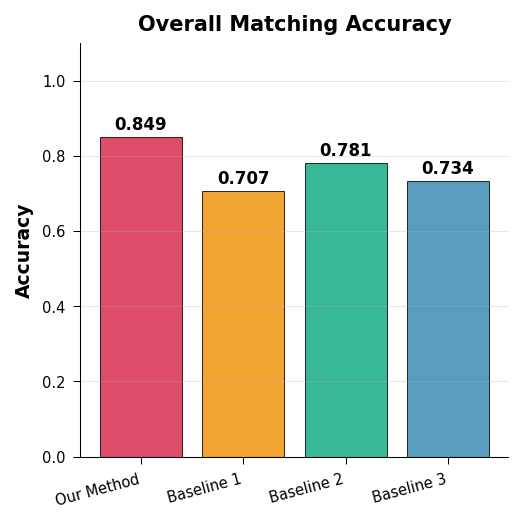

  Saved: baseline_comparison_results/method_comparison.pdf


In [22]:
# Combine all results
all_results_df = pd.concat(all_results, ignore_index=True)

# Save results
print("\nSaving results...")
all_results_df.to_csv(f'{output_dir}/all_methods_results.csv', index=False)
print(f"  Saved: {output_dir}/all_methods_results.csv")

summary_df = pd.DataFrame([
    {'method': method, 'accuracy': acc, 'error_count': len(all_results_df[
        (all_results_df['method'] == method) & (~all_results_df['is_correct'])
    ])}
    for method, acc in accuracies.items()
])
summary_df = summary_df.sort_values('accuracy', ascending=False)
summary_df.to_csv(f'{output_dir}/methods_summary.csv', index=False)
print(f"  Saved: {output_dir}/methods_summary.csv")

# Generate visualization
print("\nGenerating visualization...")
plot_method_comparison(all_results_df, accuracies, output_dir)


In [23]:
print("\n" + "="*80)
print("Original Comparison Results")
print("="*80)

print("\nResults:")
print("-"*50)
print(f"{'Method':<40s} {'Accuracy':>10s}")
print("-"*50)

for method, acc in sorted(accuracies.items(), key=lambda x: x[1], reverse=True):
    print(f"{method:<40s} {acc:>10.4f}")

print("-"*50)

baseline_accs = [acc for method, acc in accuracies.items() if 'Baseline' in method]
best_baseline = max(baseline_accs) if baseline_accs else 0
our_acc = accuracies.get('Our Method', 0)
improvement = (our_acc - best_baseline) / best_baseline * 100 if best_baseline > 0 else 0

print(f"\nOur method improves over best baseline by: {improvement:+.2f}%")



Original Comparison Results

Results:
--------------------------------------------------
Method                                     Accuracy
--------------------------------------------------
Our Method                                   0.8489
Baseline 2                                   0.7811
Baseline 3                                   0.7337
Baseline 1                                   0.7071
--------------------------------------------------

Our method improves over best baseline by: +8.69%




Robustness Analysis - Systematic Transformations

  Testing robustness against different transformation types...

  Testing Individual Transformations

  Testing Translation: Pure translation

    Magnitude = 0 pixels...

  Evaluating Our Method: DTW+OT+Centroid with Linear Model...
    Constructing dataset...
      Processing 50/340 pairs...
      Processing 100/340 pairs...
      Processing 150/340 pairs...
      Processing 200/340 pairs...
      Processing 250/340 pairs...
      Processing 300/340 pairs...
    Dataset constructed: 6683 samples
    Training Linear Model with GroupKFold CV...
    Evaluating predictions...
    Our Method Accuracy: 0.8489

  Evaluating Baseline 1...
    Processing 50/340 pairs...
    Processing 100/340 pairs...
    Processing 150/340 pairs...
    Processing 200/340 pairs...
    Processing 250/340 pairs...
    Processing 300/340 pairs...
    Baseline 1 Accuracy: 0.7071

  Evaluating Baseline 2: Hungarian Assignment...
    Processing layer pair 1->2...


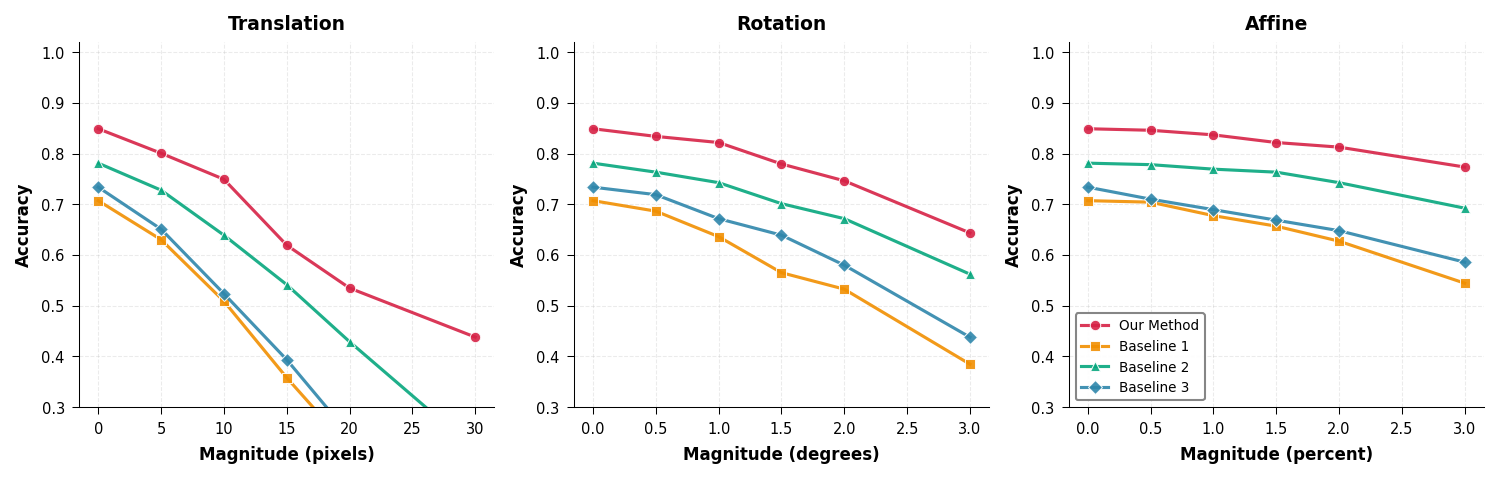

  Saved: baseline_comparison_results/robustness_analysis/robustness_individual.pdf


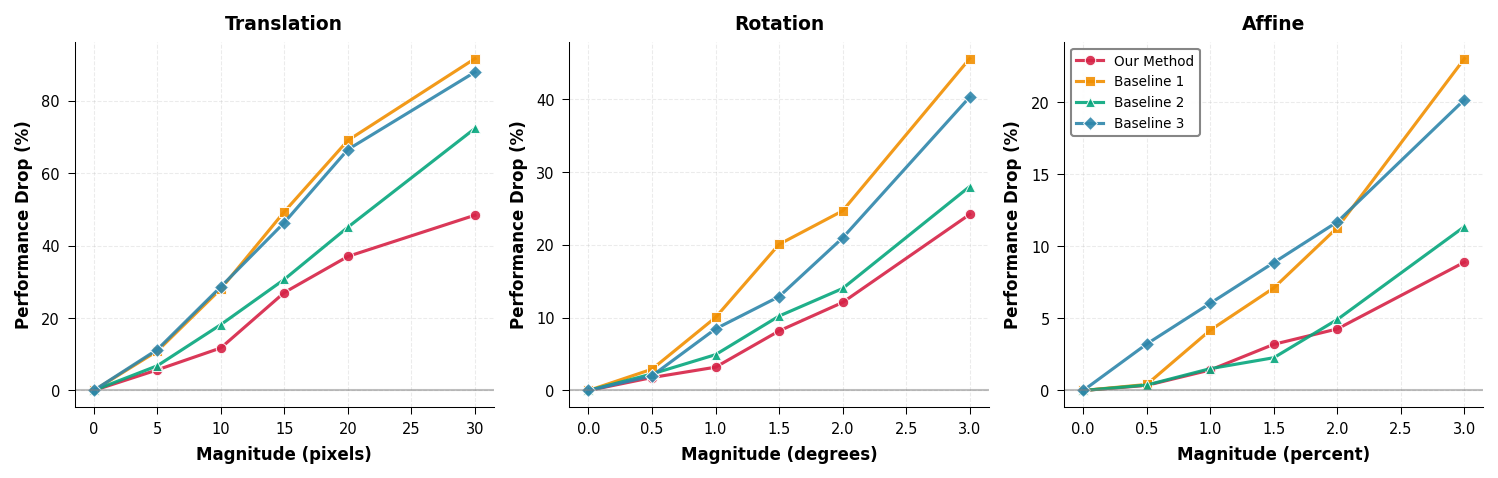

  Saved: baseline_comparison_results/robustness_analysis/robustness_degradation.pdf

  Robustness Analysis Summary

  Individual Transformations:

  Translation:
  ----------------------------------------------------------------------
    Our Method          : 0.8489 → 0.4381 (drop: 0.4109, 48.4%)
    Baseline 1          : 0.7071 → 0.0592 (drop: 0.6479, 91.6%)
    Baseline 2          : 0.7811 → 0.2160 (drop: 0.5651, 72.3%)
    Baseline 3          : 0.7337 → 0.0888 (drop: 0.6450, 87.9%)

  Rotation:
  ----------------------------------------------------------------------
    Our Method          : 0.8489 → 0.6435 (drop: 0.2054, 24.2%)
    Baseline 1          : 0.7071 → 0.3846 (drop: 0.3225, 45.6%)
    Baseline 2          : 0.7811 → 0.5621 (drop: 0.2189, 28.0%)
    Baseline 3          : 0.7337 → 0.4379 (drop: 0.2959, 40.3%)

  Affine:
  ----------------------------------------------------------------------
    Our Method          : 0.8489 → 0.7734 (drop: 0.0755, 8.9%)
    Baseline 1      

In [24]:
print("\n\n" + "="*80)
print("Robustness Analysis - Systematic Transformations")
print("="*80)

robustness_results = analyze_robustness_with_offset(
    golden_df, cells_by_slice, output_dir, 
    fixed_anchor_set_our_method, valid_anchor_set_baselines
)